# Dados e Aprendizagem Automática 26/27
### Part IX

## **K-medoids using Blobs Dataset - II**

#### Imports, installations and settings

In [1]:
import sklearn as skl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs
from sklearn_extra.cluster import KMedoids

from sklearn import metrics
from sklearn.metrics import classification_report, confusion_matrix

%matplotlib inline

#### Create the dataset using Blobs

In [2]:
data = make_blobs(n_samples = 200, n_features = 2, centers = 4, cluster_std = 1.8, random_state = 2022)

#### Define X and y

In [3]:
X = data[0]
y = data[1]

#### Visualize the data

View the first 5 lines of the data set:

In [4]:
print('X:', X[0:5, :])
print('Y:', y[0:5])

X: [[  5.88508997   2.9021639 ]
 [ -8.20429992 -11.68670283]
 [  1.9125188   -2.76746603]
 [ -9.39601207  -7.2830252 ]
 [  6.1986976    7.32152342]]
Y: [2 1 2 1 3]


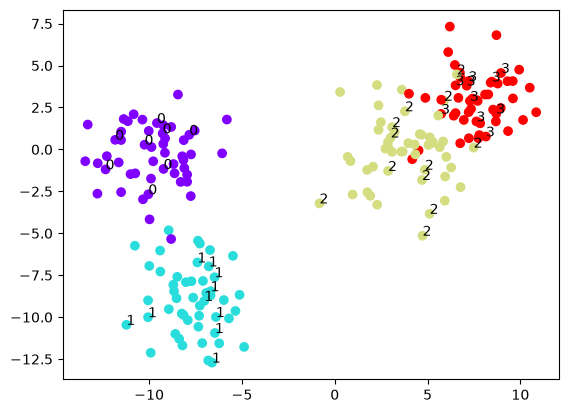

In [5]:
plt.scatter(X[:, 0], X[:, 1], c = y, cmap = 'rainbow')
for i, txt in enumerate(y):
    if i%5 == 0:
        plt.annotate(txt, (X[i, 0], X[i, 1]))

### Create the clusters

In [6]:
kmedoids = KMedoids(n_clusters = 4, random_state = 2022)

In [7]:
kmedoids.fit(X)

,n_clusters,4
,random_state,2022
,metric,'euclidean'
,method,'alternate'
,init,'heuristic'
,max_iter,300
Name,Type,Value
cluster_centers_,"ndarray[float64](4, 2)","[[-7.63,-8.84], [-9.87, 0.14], [ 3.66,-0.13], [ 7.66, 2.93]]"
inertia_,float64,419.7
labels_,"ndarray[int64](200,)","[3,0,2,...,0,1,1]"
medoid_indices_,"ndarray[int64](4,)","[ 6,137, 98, 42]"


Center of the 4 clusters

In [8]:
kmedoids.cluster_centers_

array([[-7.62795904, -8.8354951 ],
       [-9.87312876,  0.13931247],
       [ 3.65994783, -0.13260646],
       [ 7.66163195,  2.9333056 ]])

Associated labels

In [9]:
kmedoids.labels_

array([3, 0, 2, 0, 3, 1, 0, 1, 2, 2, 3, 3, 2, 3, 1, 3, 3, 3, 3, 1, 0, 2,
       3, 3, 0, 0, 2, 0, 2, 2, 3, 0, 3, 2, 3, 2, 0, 3, 0, 1, 3, 1, 3, 2,
       2, 2, 0, 0, 2, 0, 0, 2, 3, 3, 0, 2, 3, 2, 3, 1, 1, 1, 2, 2, 3, 1,
       0, 1, 1, 1, 2, 1, 2, 0, 0, 1, 1, 0, 0, 1, 3, 3, 1, 2, 0, 0, 3, 2,
       1, 0, 2, 3, 1, 2, 2, 3, 2, 1, 2, 2, 0, 3, 1, 0, 1, 2, 1, 2, 1, 1,
       3, 1, 1, 1, 2, 1, 2, 2, 0, 2, 3, 3, 3, 2, 0, 0, 3, 2, 1, 3, 0, 1,
       1, 0, 0, 0, 1, 1, 3, 0, 0, 0, 3, 2, 0, 3, 0, 1, 2, 1, 2, 2, 3, 3,
       3, 3, 3, 3, 0, 0, 0, 0, 0, 2, 3, 1, 0, 0, 3, 1, 2, 3, 3, 0, 2, 3,
       2, 0, 0, 1, 2, 0, 1, 1, 0, 1, 3, 3, 1, 2, 1, 2, 2, 0, 1, 3, 1, 0,
       1, 1])

#### Visualize the clusters

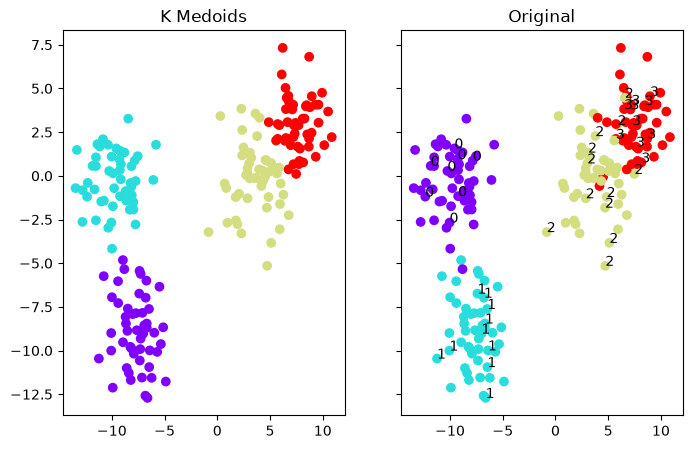

In [10]:
f, (ax1, ax2) = plt.subplots(1, 2, sharey=True,figsize=(8,5))
ax1.set_title('K Medoids')
ax1.scatter(X[:, 0], X[:, 1], c = kmedoids.labels_, cmap = 'rainbow')
ax2.set_title("Original")
ax2.scatter(X[:, 0], X[:, 1], c = y, cmap = 'rainbow')
for i, txt in enumerate(y):
    if i%5 == 0:
        plt.annotate(txt, (X[i, 0], X[i, 1]))
plt.savefig("KMedoids.png")

##### Align K-Medoids prediction class with real values

In [11]:
y_pred = kmedoids.predict(X)

In [12]:
y_pred

array([3, 0, 2, 0, 3, 1, 0, 1, 2, 2, 3, 3, 2, 3, 1, 3, 3, 3, 3, 1, 0, 2,
       3, 3, 0, 0, 2, 0, 2, 2, 3, 0, 3, 2, 3, 2, 0, 3, 0, 1, 3, 1, 3, 2,
       2, 2, 0, 0, 2, 0, 0, 2, 3, 3, 0, 2, 3, 2, 3, 1, 1, 1, 2, 2, 3, 1,
       0, 1, 1, 1, 2, 1, 2, 0, 0, 1, 1, 0, 0, 1, 3, 3, 1, 2, 0, 0, 3, 2,
       1, 0, 2, 3, 1, 2, 2, 3, 2, 1, 2, 2, 0, 3, 1, 0, 1, 2, 1, 2, 1, 1,
       3, 1, 1, 1, 2, 1, 2, 2, 0, 2, 3, 3, 3, 2, 0, 0, 3, 2, 1, 3, 0, 1,
       1, 0, 0, 0, 1, 1, 3, 0, 0, 0, 3, 2, 0, 3, 0, 1, 2, 1, 2, 2, 3, 3,
       3, 3, 3, 3, 0, 0, 0, 0, 0, 2, 3, 1, 0, 0, 3, 1, 2, 3, 3, 0, 2, 3,
       2, 0, 0, 1, 2, 0, 1, 1, 0, 1, 3, 3, 1, 2, 1, 2, 2, 0, 1, 3, 1, 0,
       1, 1])

In [13]:
y

array([2, 1, 2, 1, 3, 0, 1, 0, 2, 2, 3, 3, 2, 3, 0, 3, 3, 3, 3, 0, 1, 2,
       3, 3, 1, 1, 3, 1, 2, 2, 3, 1, 3, 3, 3, 2, 1, 3, 1, 0, 3, 0, 3, 2,
       2, 2, 1, 1, 2, 1, 1, 2, 3, 3, 1, 2, 3, 2, 3, 0, 0, 0, 2, 2, 3, 0,
       1, 0, 0, 0, 2, 0, 2, 1, 1, 0, 0, 1, 1, 0, 2, 3, 0, 2, 1, 1, 3, 2,
       0, 1, 2, 3, 0, 2, 2, 3, 2, 0, 2, 2, 1, 3, 0, 1, 0, 2, 0, 2, 0, 0,
       3, 0, 0, 0, 2, 0, 2, 2, 1, 2, 3, 3, 3, 2, 1, 1, 3, 2, 0, 3, 1, 0,
       0, 1, 1, 1, 0, 0, 3, 1, 1, 1, 3, 2, 1, 3, 1, 0, 2, 0, 2, 2, 3, 3,
       2, 3, 3, 3, 0, 1, 1, 1, 1, 2, 3, 0, 1, 1, 3, 0, 2, 3, 3, 1, 2, 3,
       2, 1, 1, 0, 2, 1, 0, 0, 1, 0, 3, 3, 0, 2, 0, 3, 2, 1, 0, 2, 0, 1,
       0, 0])

In [14]:
y_pred = np.where(y_pred==1, 10, y_pred)
y_pred = np.where(y_pred==0, 1, y_pred)
y_pred = np.where(y_pred==10, 0, y_pred)

In [15]:
y_pred

array([3, 1, 2, 1, 3, 0, 1, 0, 2, 2, 3, 3, 2, 3, 0, 3, 3, 3, 3, 0, 1, 2,
       3, 3, 1, 1, 2, 1, 2, 2, 3, 1, 3, 2, 3, 2, 1, 3, 1, 0, 3, 0, 3, 2,
       2, 2, 1, 1, 2, 1, 1, 2, 3, 3, 1, 2, 3, 2, 3, 0, 0, 0, 2, 2, 3, 0,
       1, 0, 0, 0, 2, 0, 2, 1, 1, 0, 0, 1, 1, 0, 3, 3, 0, 2, 1, 1, 3, 2,
       0, 1, 2, 3, 0, 2, 2, 3, 2, 0, 2, 2, 1, 3, 0, 1, 0, 2, 0, 2, 0, 0,
       3, 0, 0, 0, 2, 0, 2, 2, 1, 2, 3, 3, 3, 2, 1, 1, 3, 2, 0, 3, 1, 0,
       0, 1, 1, 1, 0, 0, 3, 1, 1, 1, 3, 2, 1, 3, 1, 0, 2, 0, 2, 2, 3, 3,
       3, 3, 3, 3, 1, 1, 1, 1, 1, 2, 3, 0, 1, 1, 3, 0, 2, 3, 3, 1, 2, 3,
       2, 1, 1, 0, 2, 1, 0, 0, 1, 0, 3, 3, 0, 2, 0, 2, 2, 1, 0, 3, 0, 1,
       0, 0])

#### Redo the visualizations

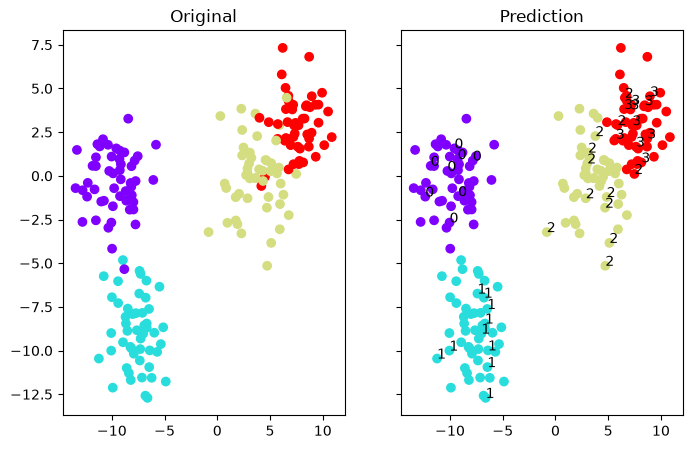

In [16]:
f, (ax1, ax2) = plt.subplots(1, 2, sharey = True, figsize = (8, 5))
ax1.set_title('Original')
ax1.scatter(X[:, 0], X[:, 1], c = y, cmap = 'rainbow')
ax2.set_title("Prediction")
ax2.scatter(X[:, 0], X[:, 1], c = y_pred, cmap = 'rainbow')
for i, txt in enumerate(y):
    if i%5 == 0:
        plt.annotate(txt, (X[i, 0], X[i, 1]))
plt.savefig("KMedoid_pred.png")

#### Evaluate the model

In [17]:
print(confusion_matrix(y, y_pred))

[[49  1  0  0]
 [ 0 50  0  0]
 [ 0  0 46  4]
 [ 0  0  3 47]]


In [18]:
print(classification_report(y, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.98      0.99        50
           1       0.98      1.00      0.99        50
           2       0.94      0.92      0.93        50
           3       0.92      0.94      0.93        50

    accuracy                           0.96       200
   macro avg       0.96      0.96      0.96       200
weighted avg       0.96      0.96      0.96       200



In [19]:
print(f"Homogeneity: {metrics.homogeneity_score(y, y_pred):.3f}")
print(f"Completeness: {metrics.completeness_score(y, y_pred):.3f}")
print(f"V-measure: {metrics.v_measure_score(y, y_pred):.3f}")
print(f"Adjusted Rand Index: {metrics.adjusted_rand_score(y, y_pred):.3f}")
print(f"Adjusted Mutual Information: {metrics.adjusted_mutual_info_score(y, y_pred):.3f}")
print(f"Silhouette Coefficient: {metrics.silhouette_score(X, y_pred):.3f}")

Homogeneity: 0.891
Completeness: 0.891
V-measure: 0.891
Adjusted Rand Index: 0.898
Adjusted Mutual Information: 0.889
Silhouette Coefficient: 0.559


#### K-Means vs. K-Medoids — *Are these two models comparable?*
Sim. Neste dataset os dois têm **exatamente os mesmos resultados**: a mesma matriz de confusão, accuracy de 0.96, ARI de 0.898 e Silhouette de 0.559. Os grupos são compactos, de forma esférica e quase sem outliers, por isso a média (centróide) e o ponto mais central (medóide) de cada cluster ficam praticamente no mesmo sítio. Os centros obtidos são quase iguais.

As diferenças aparecem quando há outliers ou ruído:
- o **K-Medoids** é mais robusto, porque o centro tem de ser um ponto real do dataset e não é "puxado" pelos valores extremos;
- em troca, tem um **custo computacional maior**, porque compara pares de pontos.